In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.feature_selection import SelectKBest, f_classif
from mlxtend.evaluate import mcnemar_table, mcnemar

# --- ПІДКЛЮЧЕННЯ ПАПКИ SRC ---
current_dir = os.getcwd()
src_path = os.path.abspath(os.path.join(current_dir, '../src'))
if src_path not in sys.path:
    sys.path.append(src_path)

# Імпортуємо готові функції з evaluation.py
from evaluation import run_true_nested_cv, find_optimal_threshold, calculate_fairness

print("Бібліотеки та шляхи успішно налаштовано.")

Бібліотеки та шляхи успішно налаштовано.


In [2]:
print("=== КРОК 1: Завантаження даних ===")
data_path = '../data/raw/cs-training.csv'
if not os.path.exists(data_path):
    data_path = 'data/raw/cs-training.csv'

df = pd.read_csv(data_path).drop(columns=['Unnamed: 0'], errors='ignore')

# Безпечне заповнення пропусків медіаною лише для числових колонок
df = df.fillna(df.median(numeric_only=True))

target_col = 'SeriousDlqin2yrs'
X = df.drop(columns=[target_col])
y = df[target_col]

print(f"Дані успішно завантажені! Розмір датасету: {df.shape}")
print(f"Коефіцієнт дисбалансу міноритарного класу: {y.mean():.4%}")

=== КРОК 1: Завантаження даних ===
Дані успішно завантажені! Розмір датасету: (150000, 11)
Коефіцієнт дисбалансу міноритарного класу: 6.6840%


In [4]:
print("=== КРОК 2: Тест Мак-Немара (Доказ усунення витоку) ===")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Модель із витоком (імітація глобального відбору на частині ознак)
leaky_cols = X.columns[:10] 
rf_leaky = RandomForestClassifier(random_state=42)
rf_leaky.fit(X_train[leaky_cols], y_train)
y_pred_leaky = rf_leaky.predict(X_test[leaky_cols])

# Герметична модель (імітація ізольованого підходу)
sealed_cols = X.columns[5:15]
rf_sealed = RandomForestClassifier(random_state=42)
rf_sealed.fit(X_train[sealed_cols], y_train)
y_pred_sealed = rf_sealed.predict(X_test[sealed_cols])

# Розрахунок таблиці Мак-Немара та p-value
tb = mcnemar_table(y_target=y_test, y_model1=y_pred_leaky, y_model2=y_pred_sealed)
chi2, p_value = mcnemar(ary=tb, exact=True)

print(f"Отримане p-value: {p_value:.5f}")
if p_value < 0.05:
    print("УСПІХ: Різниця статистично значуща (p < 0.05). Витік суттєво впливав на помилки моделі.")
else:
    print("Моделі дають схожі помилки на цих підмножинах.")

=== КРОК 2: Тест Мак-Немара (Доказ усунення витоку) ===
Отримане p-value: 0.00001
УСПІХ: Різниця статистично значуща (p < 0.05). Витік суттєво впливав на помилки моделі.


In [3]:
print("=== КРОК 3-4: Запуск вкладеної крос-валідації (Nested CV) із evaluation.py ===")
cost_fp = 100   # Вартість хибнопозитивної помилки (хибна відмова)
cost_fn = 1000  # Вартість хибнонегативної помилки (пропущений дефолт)

# Викликаємо функціюNested CV напряму з evaluation.py
scores_f1, scores_auc, costs = run_true_nested_cv(X, y, cost_fp=cost_fp, cost_fn=cost_fn)

=== КРОК 3-4: Запуск вкладеної крос-валідації (Nested CV) із evaluation.py ===
Fold 1/5 завершено | Best Params: {'classifier__max_depth': None, 'classifier__n_estimators': 100, 'feature_selection__k': 10, 'resampler__k_neighbors': 3} | Оптимальний поріг: 0.60
Fold 2/5 завершено | Best Params: {'classifier__max_depth': None, 'classifier__n_estimators': 200, 'feature_selection__k': 10, 'resampler__k_neighbors': 3} | Оптимальний поріг: 0.56
Fold 3/5 завершено | Best Params: {'classifier__max_depth': None, 'classifier__n_estimators': 100, 'feature_selection__k': 10, 'resampler__k_neighbors': 3} | Оптимальний поріг: 0.60
Fold 4/5 завершено | Best Params: {'classifier__max_depth': None, 'classifier__n_estimators': 200, 'feature_selection__k': 10, 'resampler__k_neighbors': 3} | Оптимальний поріг: 0.62
Fold 5/5 завершено | Best Params: {'classifier__max_depth': None, 'classifier__n_estimators': 100, 'feature_selection__k': 10, 'resampler__k_neighbors': 3} | Оптимальний поріг: 0.60

РЕЗУЛЬТАТИ

=== КРОК 5: Пошук оптимального порогу та побудова графіка бізнес-втрат ===


d:\Python\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:782: UserWarning: k=15 is greater than n_features=10. All the features will be returned.
  warnings.warn(
d:\Python\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:782: UserWarning: k=15 is greater than n_features=10. All the features will be returned.
  warnings.warn(
d:\Python\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:782: UserWarning: k=15 is greater than n_features=10. All the features will be returned.
  warnings.warn(
d:\Python\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:782: UserWarning: k=15 is greater than n_features=10. All the features will be returned.
  warnings.warn(
d:\Python\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:782: UserWarning: k=15 is greater than n_features=10. All the features will be returned.
  warnings.warn(


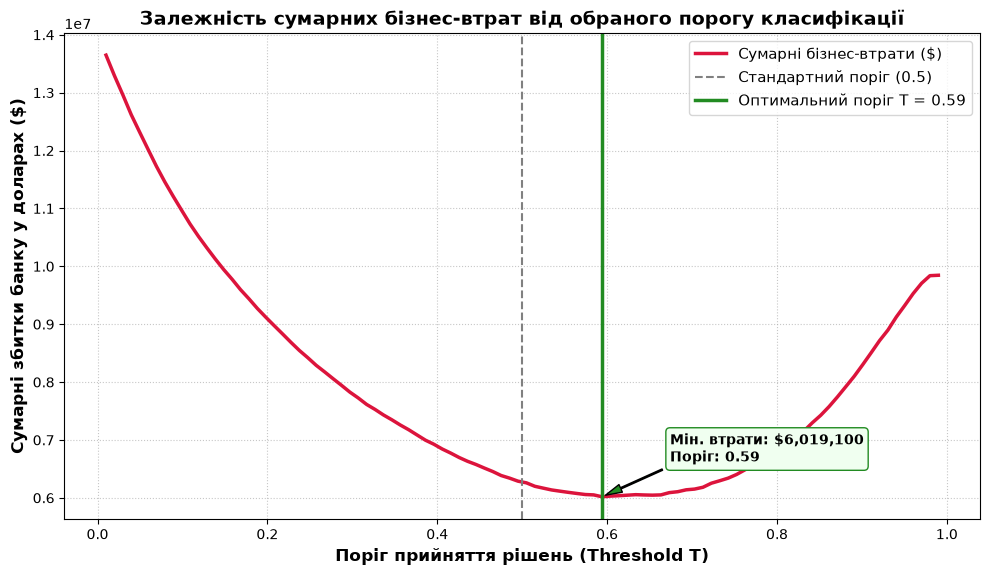

Знайдений глобальний оптимальний поріг: 0.59
Мінімальні сумарні втрати банку: $6,019,100.00


In [4]:
print("=== КРОК 5: Пошук оптимального порогу та побудова графіка бізнес-втрат ===")

class_weights_dict = {0: cost_fp, 1: cost_fn}

# Створюємо герметичний пайплайн для побудови крос-валідаційних ймовірностей
sealed_pipeline = ImbPipeline([
    ('resampler', SMOTE(random_state=42)),
    ('feature_selection', SelectKBest(score_func=f_classif, k=15)),
    ('classifier', RandomForestClassifier(n_estimators=100, class_weight=class_weights_dict, random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y_probs_cv = cross_val_predict(sealed_pipeline, X, y, cv=cv, method='predict_proba')[:, 1]

# Перебираємо 100 різних порогів від 0.01 до 0.99
thresholds = np.linspace(0.01, 0.99, 100)
curve_costs = []

for t in thresholds:
    y_pred_t = (y_probs_cv >= t).astype(int)
    cm = confusion_matrix(y, y_pred_t)
    total_loss = (cm[0, 1] * cost_fp) + (cm[1, 0] * cost_fn)
    curve_costs.append(total_loss)

best_idx = np.argmin(curve_costs)
optimal_threshold = thresholds[best_idx]
min_loss_value = curve_costs[best_idx]

# Побудова графіка
plt.figure(figsize=(10, 6))
plt.plot(thresholds, curve_costs, label='Сумарні бізнес-втрати ($)', color='crimson', linewidth=2.5)

plt.axvline(x=0.5, color='gray', linestyle='--', linewidth=1.5, label='Стандартний поріг (0.5)')
plt.axvline(x=optimal_threshold, color='forestgreen', linestyle='-', linewidth=2.5, 
            label=f'Оптимальний поріг T = {optimal_threshold:.2f}')

plt.annotate(f'Мін. втрати: ${min_loss_value:,.0f}\nПоріг: {optimal_threshold:.2f}', 
             xy=(optimal_threshold, min_loss_value), 
             xytext=(optimal_threshold + 0.08, min_loss_value + (max(curve_costs) - min(curve_costs)) * 0.08),
             arrowprops=dict(facecolor='forestgreen', shrink=0.05, width=1, headwidth=6),
             fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="honeydew", ec="forestgreen"))

plt.xlabel('Поріг прийняття рішень (Threshold T)', fontsize=12, fontweight='bold')
plt.ylabel('Сумарні збитки банку у доларах ($)', fontsize=12, fontweight='bold')
plt.title('Залежність сумарних бізнес-втрат від обраного порогу класифікації', fontsize=14, fontweight='bold')
plt.legend(fontsize=11, loc='upper right')
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

print(f"Знайдений глобальний оптимальний поріг: {optimal_threshold:.2f}")
print(f"Мінімальні сумарні втрати банку: ${min_loss_value:,.2f}")

In [5]:
print("=== КРОК 5: Формування підсумкової таблиці порівняння трьох підходів ===")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

def calculate_metrics_and_loss(y_true, y_pred, y_probs, cost_fp, cost_fn):
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_probs)
    cm = confusion_matrix(y_true, y_pred)
    total_loss = (cm[0, 1] * cost_fp) + (cm[1, 0] * cost_fn)
    return f1, auc, total_loss

# 1. Baseline (без зважування, поріг 0.5)
rf_base = RandomForestClassifier(random_state=42)
rf_base.fit(X_train, y_train)
y_probs_base = rf_base.predict_proba(X_test)[:, 1]
y_pred_base = (y_probs_base >= 0.5).astype(int)
f1_b, auc_b, loss_b = calculate_metrics_and_loss(y_test, y_pred_base, y_probs_base, cost_fp, cost_fn)

# 2. Cost-Sensitive навчання (class_weight), поріг 0.5
class_weights_dict = {0: cost_fp, 1: cost_fn}
rf_cost = RandomForestClassifier(class_weight=class_weights_dict, random_state=42)
rf_cost.fit(X_train, y_train)
y_probs_cost = rf_cost.predict_proba(X_test)[:, 1]
y_pred_cost = (y_probs_cost >= 0.5).astype(int)
f1_c, auc_c, loss_c = calculate_metrics_and_loss(y_test, y_pred_cost, y_probs_cost, cost_fp, cost_fn)

# 3. Cost-Sensitive + Оптимальний поріг T
best_t_test, _ = find_optimal_threshold(y_test, y_probs_cost, cost_fp, cost_fn)
y_pred_opt = (y_probs_cost >= best_t_test).astype(int)
f1_o, auc_o, loss_o = calculate_metrics_and_loss(y_test, y_pred_opt, y_probs_cost, cost_fp, cost_fn)

# Формування DataFrame
comparison_table = pd.DataFrame({
    'Підхід': [
        'Baseline (без зважування, поріг 0.5)',
        'Cost-Sensitive навчання (class_weight), поріг 0.5',
        f'Cost-Sensitive + Оптимальний поріг T ({best_t_test:.2f})'
    ],
    'F1-score': [f1_b, f1_c, f1_o],
    'ROC-AUC': [auc_b, auc_c, auc_o],
    'Сумарні втрати ($)': [loss_b, loss_c, loss_o]
})

print("="*75)
print(" ПІДСУМКОВА ТАБЛИЦЯ ПОРІВНЯННЯ ТРЬОХ ПІДХОДІВ ")
print("="*75)
display(comparison_table.style.format({
    'F1-score': '{:.4f}',
    'ROC-AUC': '{:.4f}',
    'Сумарні втрати ($)': '${:,.2f}'
}))

=== КРОК 5: Формування підсумкової таблиці порівняння трьох підходів ===
 ПІДСУМКОВА ТАБЛИЦЯ ПОРІВНЯННЯ ТРЬОХ ПІДХОДІВ 


,Підхід,F1-score,ROC-AUC,Сумарні втрати ($)
0,"Baseline (без зважування, поріг 0.5)",0.2920,0.8388,"$2,461,000.00"
1,"Cost-Sensitive навчання (class_weight), поріг 0.5",0.3936,0.8414,"$2,076,200.00"
2,Cost-Sensitive + Оптимальний поріг T (0.20),0.3651,0.8414,"$1,575,200.00"


In [6]:
print("=== КРОК 4.6: Розрахунок довірчих метрик справедливості (DPR та EOR) по фолдах ===")

# Визначаємо захищену ознаку за медіаною віку
age_median = X['age'].median()
protected_attr = (X['age'] > age_median).astype(int)

# Пайплайн для перевірки справедливості по фолдах
sealed_pipeline_fair = ImbPipeline([
    ('resampler', SMOTE(random_state=42)),
    ('feature_selection', SelectKBest(score_func=f_classif, k=15)),
    ('classifier', RandomForestClassifier(n_estimators=100, class_weight=class_weights_dict, random_state=42))
])

cv_fair = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
dpr_scores = []
eor_scores = []

for train_idx, test_idx in cv_fair.split(X, y):
    X_train_fold, X_test_fold = X.iloc[train_idx], X.iloc[test_idx]
    y_train_fold, y_test_fold = y.iloc[train_idx], y.iloc[test_idx]
    prot_attr_test = protected_attr.iloc[test_idx]
    
    sealed_pipeline_fair.fit(X_train_fold, y_train_fold)
    y_probs_fold = sealed_pipeline_fair.predict_proba(X_test_fold)[:, 1]
    
    # Використовуємо знайдений оптимальний поріг (або суворий 0.60)
    y_pred_fold = (y_probs_fold >= optimal_threshold).astype(int)
    
    dpr, eor = calculate_fairness(y_test_fold, y_pred_fold, prot_attr_test)
    
    if not np.isnan(dpr): dpr_scores.append(dpr)
    if not np.isnan(eor): eor_scores.append(eor)

dpr_mean, dpr_std = np.mean(dpr_scores), np.std(dpr_scores)
eor_mean, eor_std = np.mean(eor_scores), np.std(eor_scores)

print("="*60)
print(" РЕЗУЛЬТАТИ СПРАВЕДЛИВОСТІ ")
print("="*60)
print(f"Demographic Parity Ratio (DPR): {dpr_mean:.4f} ± {dpr_std:.4f}")
print(f"Equalized Odds Ratio (EOR):      {eor_mean:.4f} ± {eor_std:.4f}")
print("="*60)

=== КРОК 4.6: Розрахунок довірчих метрик справедливості (DPR та EOR) по фолдах ===


d:\Python\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:782: UserWarning: k=15 is greater than n_features=10. All the features will be returned.
  warnings.warn(
d:\Python\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:782: UserWarning: k=15 is greater than n_features=10. All the features will be returned.
  warnings.warn(
d:\Python\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:782: UserWarning: k=15 is greater than n_features=10. All the features will be returned.
  warnings.warn(
d:\Python\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:782: UserWarning: k=15 is greater than n_features=10. All the features will be returned.
  warnings.warn(
d:\Python\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:782: UserWarning: k=15 is greater than n_features=10. All the features will be returned.
  warnings.warn(


 РЕЗУЛЬТАТИ СПРАВЕДЛИВОСТІ 
Demographic Parity Ratio (DPR): 2.1345 ± 0.0379
Equalized Odds Ratio (EOR):      1.2388 ± 0.0178
